# 01: Business questions

**Client question:** "Late deliveries seem to be hurting our customer reviews. How big is the problem,
where does it come from (regions, sellers, product categories), and can we flag at-risk orders early?"

This notebook answers the first part with SQL against the dbt marts in `warehouse/olist.duckdb`.
Run `dbt build` first. The model for flagging at-risk orders is in notebook 02.

**Definitions used throughout**
- *Delivered order:* status is `delivered` and a delivery date exists (96,470 orders).
- *Late:* delivered on a later calendar date than the date promised at purchase.
- *Trend window:* purchase months 2017-01 to 2018-08. The months before and after have almost no orders.

In [1]:
import sys
from pathlib import Path

import duckdb
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from statsmodels.tsa.holtwinters import ExponentialSmoothing

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.chart_style import BLUE, GREY, ORANGE, TEXT_MUTED, register_template

register_template()
# Static PNG output so the charts are visible on GitHub without running the notebook.
pio.renderers.default = "png"
pio.renderers["png"].width = 900
pio.renderers["png"].height = 460

FIGURES = PROJECT_ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(PROJECT_ROOT / "warehouse" / "olist.duckdb"), read_only=True)


def sql(query: str) -> pd.DataFrame:
    """Run a query against the warehouse and return a DataFrame."""
    return con.sql(query).df()


def show(fig: go.Figure, name: str) -> None:
    """Display a chart and save a copy to reports/figures/."""
    fig.write_image(FIGURES / f"{name}.png", width=900, height=460, scale=2)
    fig.show()


pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Q1. What share of delivered orders arrive late, and how has that changed month by month?

In [2]:
overall = sql("""
    select
        count(*) filter (where is_delivered)                      as delivered_orders,
        count(*) filter (where is_late)                           as late_orders,
        100.0 * count(*) filter (where is_late)
              / count(*) filter (where is_delivered)              as late_pct,
        median(days_late) filter (where is_late)                  as median_days_late_when_late
    from marts.fct_orders
""")
overall

,delivered_orders,late_orders,late_pct,median_days_late_when_late
0,96470,6534,6.77,7.00


In [3]:
monthly = sql("""
    select month, delivered_orders, late_orders, 100 * late_rate as late_pct
    from marts.mart_monthly_kpis
    where month between date '2017-01-01' and date '2018-08-01'
    order by month
""")
monthly

,month,delivered_orders,late_orders,late_pct
0,2017-01-01,750,22,2.93
1,2017-02-01,1653,49,2.96
2,2017-03-01,2546,116,4.56
3,2017-04-01,2303,151,6.56
4,2017-05-01,3545,106,2.99
5,2017-06-01,3135,95,3.03
6,2017-07-01,3872,108,2.79
7,2017-08-01,4193,122,2.91
8,2017-09-01,4150,182,4.39
9,2017-10-01,4478,187,4.18


In [4]:
peaks = monthly.nlargest(3, "late_pct")
peak_share = 100 * peaks["late_orders"].sum() / monthly["late_orders"].sum()
print(f"Three worst months: {', '.join(peaks['month'].dt.strftime('%Y-%m'))}")
print(f"They hold {peaks['late_orders'].sum():,} of {monthly['late_orders'].sum():,} late orders "
      f"in the window ({peak_share:.1f}%), but only "
      f"{100 * peaks['delivered_orders'].sum() / monthly['delivered_orders'].sum():.1f}% of delivered orders.")

Three worst months: 2018-03, 2018-02, 2017-11
They hold 3,158 of 6,531 late orders in the window (48.4%), but only 21.7% of delivered orders.


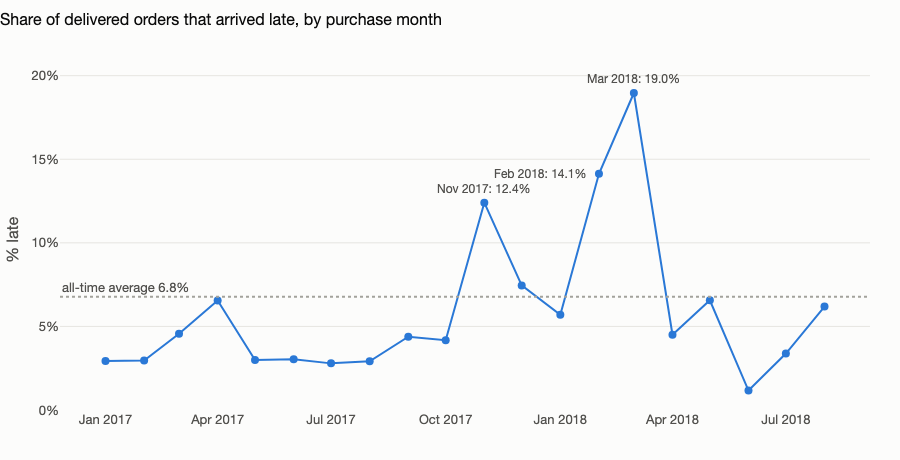

In [5]:
fig = go.Figure(go.Scatter(
    x=monthly["month"], y=monthly["late_pct"], mode="lines+markers", line_color=BLUE,
    hovertemplate="%{x|%b %Y}: %{y:.1f}% late<extra></extra>",
))
for _, row in peaks.iterrows():
    # Feb 2018 sits on the rising line to March, so its label goes to the left
    left = row["month"].month == 2
    fig.add_annotation(x=row["month"], y=row["late_pct"], text=f"{row['month']:%b %Y}: {row['late_pct']:.1f}%",
                       showarrow=False, xanchor="right" if left else "center", xshift=-10 if left else 0,
                       yshift=0 if left else 14, font=dict(color=TEXT_MUTED, size=12))
fig.add_hline(y=overall.loc[0, "late_pct"], line_dash="dot", line_color=GREY,
              annotation_text=f"all-time average {overall.loc[0, 'late_pct']:.1f}%",
              annotation_position="top left", annotation_font_color=TEXT_MUTED)
fig.update_layout(title="Share of delivered orders that arrived late, by purchase month",
                  yaxis_title="% late", yaxis_ticksuffix="%", yaxis_rangemode="tozero")
show(fig, "q1_late_rate_by_month")

**Note.** Orders are grouped by purchase month. A few orders from the last months were still in transit
when the data was extracted (47 from August 2018 had status `shipped`), so the most recent late rates may be
slightly understated.

## Q2. How much lower are reviews for late orders, and what share of late orders get 1–2 stars?

In [6]:
reviews = sql("""
    select
        case when is_late then 'late' else 'on time' end                       as delivery,
        count(*)                                                               as orders,
        count(review_score)                                                    as reviewed_orders,
        avg(review_score)                                                      as avg_review,
        100.0 * count(*) filter (where review_score <= 2) / count(review_score) as pct_1_2_stars,
        100.0 * count(*) filter (where review_score = 5) / count(review_score)  as pct_5_stars
    from marts.fct_orders
    where is_delivered
    group by 1
    order by 1 desc
""")
reviews

,delivery,orders,reviewed_orders,avg_review,pct_1_2_stars,pct_5_stars
0,on time,89936,89443,4.29,9.27,62.27
1,late,6534,6381,2.27,62.42,16.53


In [7]:
by_days_late = sql("""
    select
        case when days_late <= 0  then 'on time'
             when days_late <= 3  then '1-3 days late'
             when days_late <= 7  then '4-7 days late'
             when days_late <= 14 then '8-14 days late'
             else '15+ days late' end                                          as bucket,
        count(*)                                                               as orders,
        avg(review_score)                                                      as avg_review,
        100.0 * count(*) filter (where review_score <= 2) / count(review_score) as pct_1_2_stars
    from marts.fct_orders
    where is_delivered
    group by 1
    order by min(days_late)
""")
by_days_late

,bucket,orders,avg_review,pct_1_2_stars
0,on time,89936,4.29,9.27
1,1-3 days late,1870,3.29,32.13
2,4-7 days late,1802,2.10,67.68
3,8-14 days late,1478,1.67,80.15
4,15+ days late,1384,1.72,78.35


In [8]:
low_share = sql("""
    select
        count(*) filter (where review_score <= 2)                   as low_reviews,
        count(*) filter (where review_score <= 2 and is_late)       as low_reviews_late,
        100.0 * count(*) filter (where review_score <= 2 and is_late)
              / count(*) filter (where review_score <= 2)           as pct_of_low_reviews_that_are_late
    from marts.fct_orders
    where is_delivered
""")
low_share

,low_reviews,low_reviews_late,pct_of_low_reviews_that_are_late
0,12272,3983,32.46


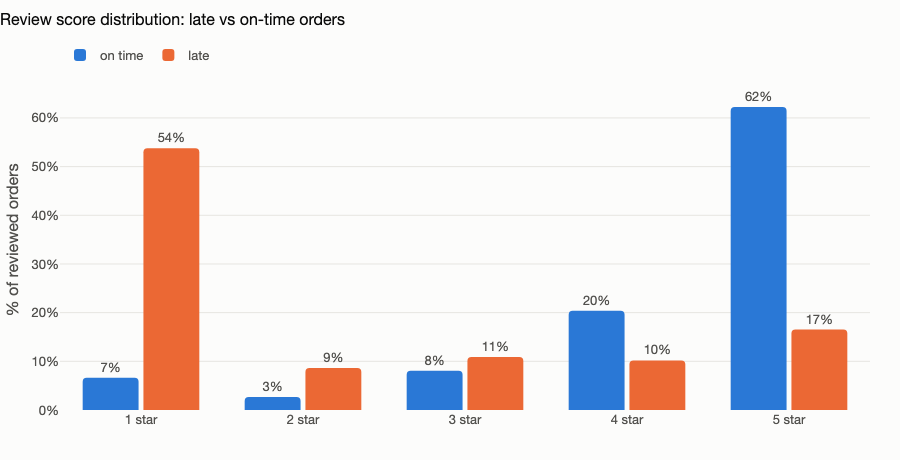

In [9]:
dist = sql("""
    select
        case when is_late then 'late' else 'on time' end as delivery,
        review_score,
        100.0 * count(*) / sum(count(*)) over (partition by is_late) as pct
    from marts.fct_orders
    where is_delivered and review_score is not null
    group by is_late, review_score
    order by review_score
""")
fig = go.Figure()
for label, colour in [("on time", BLUE), ("late", ORANGE)]:
    part = dist[dist["delivery"] == label]
    fig.add_bar(x=part["review_score"].astype(str) + " star", y=part["pct"], name=label, marker_color=colour,
                text=part["pct"].map(lambda v: f"{v:.0f}%"), textposition="outside",
                textfont_color=TEXT_MUTED, hovertemplate="%{x}: %{y:.1f}%<extra>" + label + "</extra>")
fig.update_layout(title="Review score distribution: late vs on-time orders", barmode="group",
                  yaxis_title="% of reviewed orders", yaxis_ticksuffix="%", bargroupgap=0.08)
show(fig, "q2_review_distribution")

## Q3. Which customer states and seller-to-customer routes have the highest late rates?

The route uses the state of the order's main seller (the seller with the highest item value in the order).
Only routes with at least 100 delivered orders are shown.

In [10]:
states = sql("""
    select
        customer_state,
        count(*)                                     as delivered_orders,
        count(*) filter (where is_late)              as late_orders,
        100.0 * count(*) filter (where is_late) / count(*) as late_pct,
        avg(promised_days)                           as avg_promised_days,
        avg(delivery_days)                           as avg_delivery_days
    from marts.fct_orders
    where is_delivered
    group by 1
    order by late_pct desc
""")
states

,customer_state,delivered_orders,late_orders,late_pct,avg_promised_days,avg_delivery_days
0,AL,397,85,21.41,33.21,24.50
1,MA,717,125,17.43,31.08,21.51
2,SE,335,51,15.22,31.48,21.46
3,PI,476,66,13.87,30.70,19.39
4,CE,1279,176,13.76,32.00,21.20
5,RR,41,5,12.20,46.63,29.34
6,BA,3256,396,12.16,30.07,19.28
7,RJ,12350,1495,12.11,27.00,15.24
8,PA,946,106,11.21,37.79,23.73
9,ES,1995,214,10.73,26.22,15.72


In [11]:
routes = sql("""
    select
        seller_state || ' → ' || customer_state       as route,
        count(*)                                     as delivered_orders,
        count(*) filter (where is_late)              as late_orders,
        100.0 * count(*) filter (where is_late) / count(*) as late_pct
    from marts.fct_orders
    where is_delivered
    group by seller_state, customer_state
    having count(*) >= 100
    order by late_pct desc
""")
print(f"{len(routes)} routes have at least 100 delivered orders")
routes.head(15)

70 routes have at least 100 delivered orders


,route,delivered_orders,late_orders,late_pct
0,SP → AL,255,61,23.92
1,MA → SP,123,25,20.33
2,SP → MA,492,93,18.90
3,SP → PI,329,54,16.41
4,SP → SE,208,34,16.35
5,PR → BA,143,21,14.69
6,SP → RJ,8155,1152,14.13
7,SP → CE,969,133,13.73
8,SP → BA,2308,297,12.87
9,SP → MS,476,59,12.39


In [12]:
# Late rate matters, but so does volume: which routes produce the most late orders?
routes.sort_values("late_orders", ascending=False).head(8)

,route,delivered_orders,late_orders,late_pct
42,SP → SP,30727,1428,4.65
6,SP → RJ,8155,1152,14.13
38,SP → MG,7437,393,5.28
8,SP → BA,2308,297,12.87
31,SP → RS,3594,238,6.62
20,SP → SC,2325,222,9.55
10,SP → ES,1459,180,12.34
44,SP → PR,3117,138,4.43


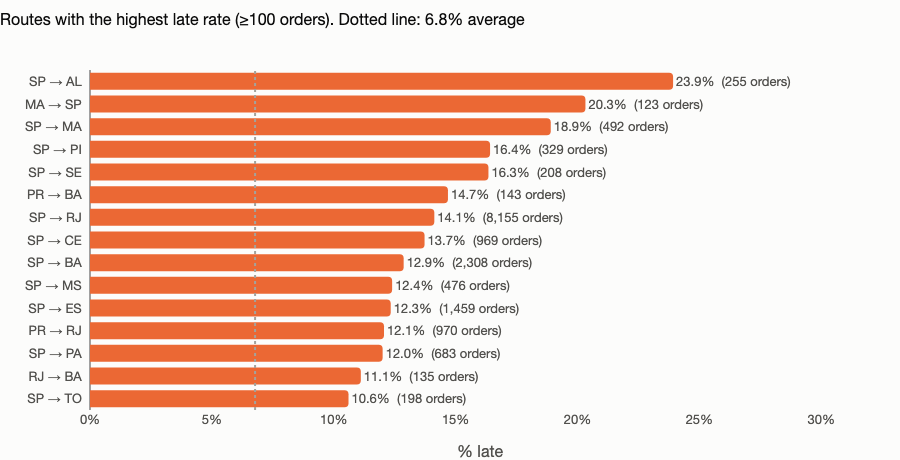

In [13]:
top_routes = routes.head(15).iloc[::-1]
fig = go.Figure(go.Bar(
    y=top_routes["route"], x=top_routes["late_pct"], orientation="h", marker_color=ORANGE,
    text=[f"{p:.1f}%  ({n:,} orders)" for p, n in zip(top_routes["late_pct"], top_routes["delivered_orders"])],
    textposition="outside", textfont_color=TEXT_MUTED,
    hovertemplate="%{y}: %{x:.1f}% late<extra></extra>",
))
fig.add_vline(x=overall.loc[0, "late_pct"], line_dash="dot", line_color=GREY)
fig.update_layout(title=f"Routes with the highest late rate (≥100 orders). Dotted line: {overall.loc[0, 'late_pct']:.1f}% average",
                  yaxis_ticksuffix="  ",
                  xaxis_title="% late", xaxis_ticksuffix="%", xaxis_range=[0, 32],
                  margin=dict(l=90), height=520)
show(fig, "q3_worst_routes")

## Q4. Do a small group of sellers cause most late orders?

Each delivered order is attributed to its main seller, so no order is counted twice.
For context, the same curve is drawn for all delivered orders: if late orders were spread in proportion
to volume, the two curves would overlap.

In [14]:
sellers = sql("""
    select
        main_seller_id                   as seller_id,
        any_value(seller_state)          as seller_state,
        count(*)                         as delivered_orders,
        count(*) filter (where is_late)  as late_orders,
        avg(review_score)                as avg_review
    from marts.fct_orders
    where is_delivered
    group by 1
""")

def cumulative_share(df: pd.DataFrame, column: str) -> pd.DataFrame:
    """Sort sellers by a column and return cumulative % of sellers and % of the column."""
    ordered = df.sort_values([column, "delivered_orders"], ascending=False).reset_index(drop=True)
    return pd.DataFrame({
        "pct_sellers": 100 * (ordered.index + 1) / len(ordered),
        "pct_total": 100 * ordered[column].cumsum() / ordered[column].sum(),
    })

late_curve = cumulative_share(sellers, "late_orders")
volume_curve = cumulative_share(sellers, "delivered_orders")

n_sellers = len(sellers)
n_with_late = int((sellers["late_orders"] > 0).sum())
sellers_for_half_late = int((late_curve["pct_total"] < 50).sum()) + 1
sellers_for_half_volume = int((volume_curve["pct_total"] < 50).sum()) + 1

print(f"Sellers with delivered orders: {n_sellers:,}; with at least one late order: {n_with_late:,}")
print(f"{sellers_for_half_late} sellers ({100 * sellers_for_half_late / n_sellers:.1f}% of sellers) "
      f"account for 50% of late orders")
print(f"{sellers_for_half_volume} sellers ({100 * sellers_for_half_volume / n_sellers:.1f}% of sellers) "
      f"account for 50% of all delivered orders")

Sellers with delivered orders: 2,958; with at least one late order: 1,273
98 sellers (3.3% of sellers) account for 50% of late orders
128 sellers (4.3% of sellers) account for 50% of all delivered orders


In [15]:
top_group = sellers.sort_values(["late_orders", "delivered_orders"], ascending=False).head(sellers_for_half_late)
rest = sellers.drop(top_group.index)
comparison = pd.DataFrame({
    "group": [f"top {sellers_for_half_late} sellers", "all other sellers"],
    "sellers": [len(top_group), len(rest)],
    "delivered_orders": [top_group["delivered_orders"].sum(), rest["delivered_orders"].sum()],
    "late_orders": [top_group["late_orders"].sum(), rest["late_orders"].sum()],
})
comparison["late_pct"] = 100 * comparison["late_orders"] / comparison["delivered_orders"]
comparison

,group,sellers,delivered_orders,late_orders,late_pct
0,top 98 sellers,98,40422,3269,8.09
1,all other sellers,2860,56048,3265,5.83


In [16]:
# Sellers with real volume and a clearly high late rate: candidates for direct intervention.
problem_sellers = sellers[(sellers["delivered_orders"] >= 50) & (sellers["late_orders"] / sellers["delivered_orders"] >= 0.15)]
print(f"{len(problem_sellers)} of {(sellers['delivered_orders'] >= 50).sum()} sellers with 50+ delivered orders "
      f"have a late rate of 15% or more; together they account for {problem_sellers['late_orders'].sum():,} late orders.")
sellers.sort_values("late_orders", ascending=False).head(10).assign(
    late_pct=lambda d: 100 * d["late_orders"] / d["delivered_orders"])

18 of 418 sellers with 50+ delivered orders have a late rate of 15% or more; together they account for 368 late orders.


,seller_id,seller_state,delivered_orders,late_orders,avg_review,late_pct
1526,4a3ca9315b744ce9f8e9374361493884,SP,1725,170,3.89,9.86
1871,1f50f920176fa81dab994f9023523100,SP,1381,124,4.16,8.98
769,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1114,118,4.17,10.59
1514,ea8482cd71df3c1969d7b9473ff13abc,SP,1122,96,4.04,8.56
2195,6560211a19b47992c3666cc44a7e94c0,SP,1802,95,3.99,5.27
2187,7c67e1448b00f6e969d365cea6b010ab,SP,971,89,3.50,9.17
772,cc419e0650a3c5ba77189a1882b7556a,SP,1647,87,4.15,5.28
400,da8622b14eb17ae2831f4ac5b9dab84a,SP,1293,87,4.20,6.73
2190,8b321bb669392f5163d04c59e235e066,SP,919,80,4.12,8.71
387,955fee9216a65b617aa5c0531780ce60,SP,1255,77,4.21,6.14


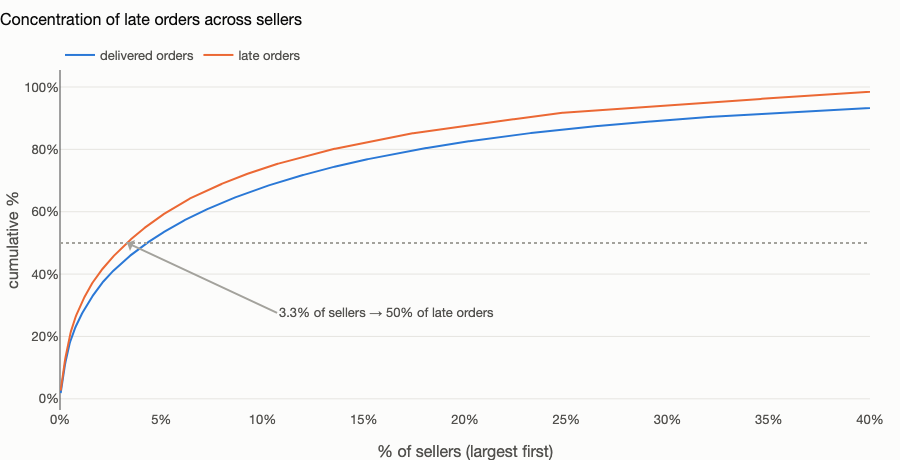

In [17]:
fig = go.Figure()
fig.add_scatter(x=volume_curve["pct_sellers"], y=volume_curve["pct_total"], mode="lines",
                name="delivered orders", line_color=BLUE,
                hovertemplate="top %{x:.1f}% of sellers: %{y:.1f}% of delivered orders<extra></extra>")
fig.add_scatter(x=late_curve["pct_sellers"], y=late_curve["pct_total"], mode="lines",
                name="late orders", line_color=ORANGE,
                hovertemplate="top %{x:.1f}% of sellers: %{y:.1f}% of late orders<extra></extra>")
fig.add_hline(y=50, line_dash="dot", line_color=GREY)
fig.add_annotation(x=100 * sellers_for_half_late / n_sellers, y=50, ax=150, ay=70, xanchor="left",
                   text=f"{100 * sellers_for_half_late / n_sellers:.1f}% of sellers → 50% of late orders",
                   font=dict(color=TEXT_MUTED), arrowcolor=GREY)
fig.update_layout(title="Concentration of late orders across sellers",
                  xaxis_title="% of sellers (largest first)", yaxis_title="cumulative %",
                  xaxis_ticksuffix="%", yaxis_ticksuffix="%", xaxis_range=[0, 40])
show(fig, "q4_seller_pareto")

## Q5. Which product categories bring the most revenue, and which have the worst reviews?

Revenue = item prices + freight for orders that were not canceled or unavailable. Each order is assigned to
its main category (the category with the highest item value), so multi-category orders count once.
For reviews, only categories with at least 500 reviewed orders are ranked, so small categories don't dominate.

In [18]:
categories = sql("""
    select
        main_category                                                    as category,
        count(*)                                                         as orders,
        sum(order_value)                                                 as revenue,
        100 * sum(order_value) / sum(sum(order_value)) over ()           as revenue_share_pct,
        avg(review_score)                                                as avg_review,
        count(review_score)                                              as reviewed_orders,
        100.0 * count(*) filter (where review_score <= 2) / count(review_score) as pct_1_2_stars,
        100.0 * count(*) filter (where is_late) / count(*) filter (where is_delivered) as late_pct
    from marts.fct_orders
    where order_status not in ('canceled', 'unavailable') and main_category is not null
    group by 1
""")
print(f"Average review across all reviewed orders: {sql('select avg(review_score) as r from marts.fct_orders')['r'][0]:.2f}")
categories.sort_values("revenue", ascending=False).head(10)

Average review across all reviewed orders: 4.09


,category,orders,revenue,revenue_share_pct,avg_review,reviewed_orders,pct_1_2_stars,late_pct
2,health_beauty,8767,"1,438,801.88",9.14,4.19,8702,12.36,7.53
65,watches_gifts,5586,"1,299,288.22",8.26,4.08,5540,14.89,7.42
57,bed_bath_table,9332,"1,248,007.99",7.93,3.98,9229,16.48,7.46
58,sports_leisure,7635,"1,146,488.70",7.29,4.19,7585,12.41,6.59
16,computers_accessories,6636,"1,052,625.11",6.69,4.04,6598,15.70,6.40
0,furniture_decor,6308,"896,839.93",5.70,4.04,6259,15.93,7.24
33,housewares,5784,"771,316.26",4.90,4.17,5745,12.48,5.42
64,cool_stuff,3585,"703,984.23",4.47,4.19,3555,11.84,5.92
43,auto,3854,"678,743.83",4.31,4.11,3834,13.93,7.33
63,garden_tools,3463,"577,808.82",3.67,4.16,3442,12.81,6.60


In [19]:
categories[categories["reviewed_orders"] >= 500].sort_values("avg_review").head(10)

,category,orders,revenue,revenue_share_pct,avg_review,reviewed_orders,pct_1_2_stars,late_pct
1,office_furniture,1269,"342,975.50",2.18,3.62,1259,22.64,8.07
45,unknown,1396,"204,138.86",1.30,3.97,1385,18.48,7.17
57,bed_bath_table,9332,"1,248,007.99",7.93,3.98,9229,16.48,7.46
34,telephony,4163,"392,772.26",2.50,4.02,4134,15.07,7.14
0,furniture_decor,6308,"896,839.93",5.70,4.04,6259,15.93,7.24
16,computers_accessories,6636,"1,052,625.11",6.69,4.04,6598,15.70,6.40
10,baby,2816,"478,413.84",3.04,4.07,2792,15.11,8.12
65,watches_gifts,5586,"1,299,288.22",8.26,4.08,5540,14.89,7.42
49,consoles_games,1049,"174,702.04",1.11,4.09,1039,13.57,6.12
3,electronics,2529,"203,843.18",1.30,4.11,2510,13.75,7.67


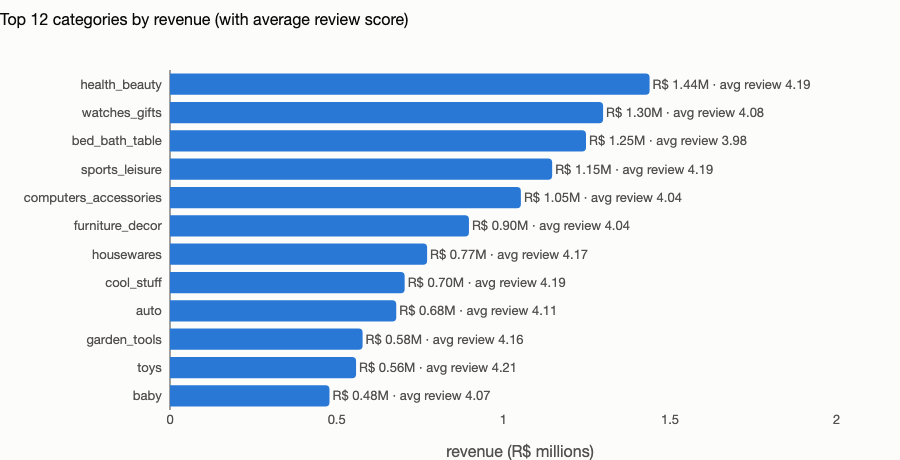

In [20]:
top_cats = categories.sort_values("revenue", ascending=False).head(12).iloc[::-1]
fig = go.Figure(go.Bar(
    y=top_cats["category"], x=top_cats["revenue"] / 1e6, orientation="h", marker_color=BLUE,
    text=[f"R$ {r / 1e6:.2f}M · avg review {s:.2f}" for r, s in zip(top_cats["revenue"], top_cats["avg_review"])],
    textposition="outside", textfont_color=TEXT_MUTED,
    hovertemplate="%{y}: R$ %{x:.2f}M<extra></extra>",
))
fig.update_layout(title="Top 12 categories by revenue (with average review score)",
                  xaxis_title="revenue (R$ millions)", xaxis_range=[0, 2.1], yaxis_ticksuffix="  ",
                  margin=dict(l=170), height=520)
show(fig, "q5_category_revenue")

## Q6. A simple 3-month forecast of monthly orders (Holt-Winters)

Training data: monthly order counts for 2017-01 to 2018-08 (20 complete months). The sparse months at the
start (2016) and end (September and October 2018) are dropped.

With only 20 months we can't estimate a yearly seasonal pattern (that needs at least two full years), so the
seasonal part of Holt-Winters is switched off. That leaves a choice about the trend, so I compare three
versions of the model on a backtest: fit on data up to May 2018, forecast June to August, and compare with
what actually happened. A naive forecast (repeat the last month) is the baseline to beat.

In [21]:
orders = sql("""
    select month, orders
    from marts.mart_monthly_kpis
    where month between date '2017-01-01' and date '2018-08-01'
    order by month
""").set_index("month")["orders"]
orders.index = pd.DatetimeIndex(orders.index, freq="MS")

MODEL_OPTIONS = {
    "level only (no trend)": dict(trend=None),
    "damped trend": dict(trend="add", damped_trend=True),
    "linear trend": dict(trend="add", damped_trend=False),
}


def fit(series: pd.Series, option: str):
    """Fit a Holt-Winters (exponential smoothing) model without a seasonal term."""
    return ExponentialSmoothing(series, seasonal=None, initialization_method="estimated",
                                **MODEL_OPTIONS[option]).fit()


def mape(actual: pd.Series, predicted) -> float:
    """Mean absolute percentage error."""
    return float((abs(actual - predicted) / actual).mean() * 100)


train, test = orders[:-3], orders[-3:]
backtest = pd.DataFrame({"actual": test})
scores = {"naive (repeat last month)": mape(test, train.iloc[-1])}
for option in MODEL_OPTIONS:
    backtest[option] = fit(train, option).forecast(3).round(0)
    scores[option] = mape(test, backtest[option])

print(pd.Series(scores, name="backtest MAPE %").round(1).to_string())
backtest

naive (repeat last month)    8.70
level only (no trend)        9.20
damped trend                28.90
linear trend                37.40


,actual,level only (no trend),damped trend,linear trend
month,,,,
2018-06-01,6167,"6,904.00","7,868.00","8,295.00"
2018-07-01,6292,"6,904.00","8,152.00","8,693.00"
2018-08-01,6512,"6,904.00","8,427.00","9,091.00"


Both trend versions overshoot badly: they learn the fast growth of 2017 and keep projecting it, while orders
actually levelled off in 2018. The level-only version (simple exponential smoothing) is the best of the three
and is close to the naive baseline. That is an honest result: in a flat period, a smoothed recent level is about
as good as it gets without more information.

In [22]:
best_option = min(MODEL_OPTIONS, key=lambda option: scores[option])
best_mape = scores[best_option]
forecast = fit(orders, best_option).forecast(3).round(0)
print(f"Chosen model: {best_option} (backtest MAPE {best_mape:.1f}%)")
forecast_table = pd.DataFrame({
    "forecast_orders": forecast,
    "rough_low": (forecast * (1 - best_mape / 100)).round(0),
    "rough_high": (forecast * (1 + best_mape / 100)).round(0),
})
forecast_table

Chosen model: level only (no trend) (backtest MAPE 9.2%)


,forecast_orders,rough_low,rough_high
2018-09-01,"6,456.00","5,860.00","7,052.00"
2018-10-01,"6,456.00","5,860.00","7,052.00"
2018-11-01,"6,456.00","5,860.00","7,052.00"


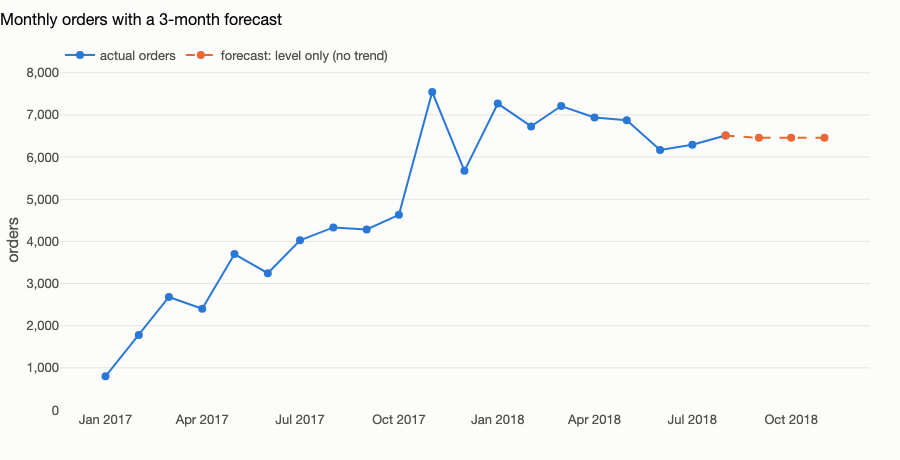

In [23]:
fig = go.Figure()
fig.add_scatter(x=orders.index, y=orders.values, mode="lines+markers", name="actual orders", line_color=BLUE,
                hovertemplate="%{x|%b %Y}: %{y:,} orders<extra></extra>")
fig.add_scatter(x=[orders.index[-1], *forecast.index], y=[orders.iloc[-1], *forecast.values],
                mode="lines+markers", name=f"forecast: {best_option}", line=dict(color=ORANGE, dash="dash"),
                hovertemplate="%{x|%b %Y}: %{y:,.0f} orders (forecast)<extra></extra>")
fig.update_layout(title="Monthly orders with a 3-month forecast",
                  yaxis_title="orders", yaxis_rangemode="tozero", yaxis_tickformat=",")
show(fig, "q6_order_forecast")

**Limitations of this forecast**
- Only 20 months of history, so there is no yearly seasonality in the model. It will **not** predict the
  November Black Friday spike (7,544 orders in November 2017, 63% above October), so the November figure
  is very likely too low.
- The backtest covers only 3 months, so the error estimate itself is rough. The low/high range above is just
  the forecast plus or minus the backtest error, not a statistical interval.
- The model only looks at past order counts. It knows nothing about marketing, prices, or the economy.
- It is a planning baseline, not a commitment. With another year of data, a seasonal Holt-Winters model or a
  model with a Black Friday indicator would be the next step.